In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go


Data Set Loading

In [5]:
df = pd.read_csv("/content/main project dataset banking.csv")

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        4519 non-null   float64
 1   job        4521 non-null   object 
 2   marital    4519 non-null   object 
 3   education  4521 non-null   object 
 4   default    4521 non-null   object 
 5   balance    4521 non-null   int64  
 6   housing    4521 non-null   object 
 7   loan       4521 non-null   object 
 8   contact    4521 non-null   object 
 9   day        4521 non-null   int64  
 10  month      4521 non-null   object 
 11  duration   4521 non-null   int64  
 12  campaign   4521 non-null   int64  
 13  pdays      4521 non-null   int64  
 14  previous   4521 non-null   int64  
 15  poutcome   4521 non-null   object 
 16  y          4517 non-null   object 
dtypes: float64(1), int64(6), object(10)
memory usage: 600.6+ KB


In [7]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30.0,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33.0,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35.0,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30.0,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59.0,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


Data Cleaning

Missing value check

In [8]:
print(df.isnull().sum())

age          2
job          0
marital      2
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            4
dtype: int64


*Remove* rows with missing target values

In [9]:
df = df.dropna(subset=["y"]).copy()

 Handle missing age using median


In [10]:
df["age"] = df["age"].fillna(df["age"].median())

Handle missing marital using mode

In [11]:
df["marital"] = df["marital"].fillna(
    df["marital"].mode()[0]
)

In [12]:
print(df.isnull().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


Datatype check and updated

In [13]:
df["age"] = df["age"].round().astype("Int64")

In [14]:
object_cols = df.select_dtypes(include=["object"]).columns
df[object_cols] = df[object_cols].astype("string")

In [15]:
print(df.dtypes)

age                   Int64
job          string[python]
marital      string[python]
education    string[python]
default      string[python]
balance               int64
housing      string[python]
loan         string[python]
contact      string[python]
day                   int64
month        string[python]
duration              int64
campaign              int64
pdays                 int64
previous              int64
poutcome     string[python]
y            string[python]
dtype: object


Check duplicate and remove

In [16]:
print(f"Duplicates removed: {df.duplicated().sum()}")

df = df.drop_duplicates()

Duplicates removed: 0


check Outliers

In [17]:
numeric_cols = [
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous"
]
outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

print(outlier_summary.round(2))


     Column     Q1      Q3     IQR  Lower Limit  Upper Limit  Outlier Count
0       age   33.0    49.0    16.0          9.0         73.0             37
1   balance   69.0  1477.0  1408.0      -2043.0       3589.0            504
2       day    9.0    21.0    12.0         -9.0         39.0              0
3  duration  104.0   329.0   225.0       -233.5        666.5            330
4  campaign    1.0     3.0     2.0         -2.0          6.0            318
5     pdays   -1.0    -1.0     0.0         -1.0         -1.0            816
6  previous    0.0     0.0     0.0          0.0          0.0            816


In [18]:
age_outliers = df[
    (df["age"] < 9) | (df["age"] > 73)
]

print("Age outlier records:", len(age_outliers))
display(age_outliers.head(10))


Age outlier records: 37


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
36,78,retired,divorced,primary,no,229,no,no,telephone,22,oct,97,1,-1,0,unknown,yes
129,77,retired,divorced,tertiary,no,4659,no,no,cellular,14,apr,161,1,-1,0,unknown,yes
166,78,housemaid,married,secondary,no,499,no,no,telephone,16,mar,80,4,-1,0,unknown,no
199,75,retired,married,secondary,no,3771,no,no,telephone,15,apr,185,1,181,2,success,yes
412,75,retired,divorced,tertiary,no,3810,yes,no,cellular,16,nov,262,1,183,1,failure,yes
477,77,retired,married,tertiary,no,7802,no,no,telephone,4,may,421,1,92,2,success,yes
573,81,retired,married,secondary,no,1,no,no,cellular,19,aug,65,5,-1,0,unknown,no
633,83,retired,married,secondary,no,0,no,no,cellular,18,mar,140,10,-1,0,unknown,no
688,80,management,married,primary,no,6483,no,no,telephone,19,oct,123,1,-1,0,unknown,no
1126,77,retired,married,secondary,no,610,no,no,cellular,13,aug,766,3,-1,0,unknown,no


In [19]:
balance_outliers = df[
    (df["balance"] < -2047.5) |
    (df["balance"] > 3596.5)
]

print("Balance outlier records:", len(balance_outliers))
display(balance_outliers.head(10))

Balance outlier records: 504


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
10,39,services,married,secondary,no,9374,yes,no,unknown,20,may,273,1,-1,0,unknown,no
16,56,technician,married,secondary,no,4073,no,no,cellular,27,aug,239,5,-1,0,unknown,no
25,41,management,married,tertiary,no,5883,no,no,cellular,20,nov,182,2,-1,0,unknown,no
30,68,retired,divorced,secondary,no,4189,no,no,telephone,14,jul,897,2,-1,0,unknown,yes
38,33,management,married,secondary,no,3935,yes,no,cellular,6,may,765,1,342,2,failure,yes
40,38,management,single,tertiary,no,11971,yes,no,unknown,17,nov,609,2,101,3,failure,no
49,61,admin.,married,unknown,no,4629,yes,no,cellular,27,jan,181,1,92,1,success,yes
62,48,management,married,tertiary,no,5887,no,no,cellular,13,aug,227,2,-1,0,unknown,no
64,56,admin.,married,secondary,no,16873,no,no,cellular,7,oct,223,1,-1,0,unknown,no


In [20]:
print("\nFinal shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nFinal data information:")
df.info()


Final shape: (4517, 17)

Missing values after cleaning:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Final data information:
<class 'pandas.core.frame.DataFrame'>
Index: 4517 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4517 non-null   Int64 
 1   job        4517 non-null   string
 2   marital    4517 non-null   string
 3   education  4517 non-null   string
 4   default    4517 non-null   string
 5   balance    4517 non-null   int64 
 6   housing    4517 non-null   string
 7   loan       4517 non-null   string
 8   contact    4517 non-null   string
 9   day        4517 non-null   int64 
 10  month      4517 non-null   string
 11  duration   4517 non-null   int64 
 1

cleaned dataset saved

In [21]:
df.to_csv("banking_cleaned.csv", index=False)


 Load cleaned data


In [22]:
df = pd.read_csv("banking_cleaned.csv")

Statistical Analysis

In [23]:
df[[
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous"
]].describe()

,age,balance,day,duration,campaign,pdays,previous
count,4517.000000,4517.000000,4517.000000,4517.000000,4517.000000,4517.000000,4517.000000
mean,41.160505,1413.964135,15.919194,264.000886,2.794554,39.802745,0.543060
std,10.564311,2978.327044,8.248326,259.926124,3.111002,100.158100,1.694235
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1477.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


Univariate analysis

1. Analyze the target variable y
How many customers subscribed and how many did not.

In [24]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True).mul(100).round(2))

y
no     3997
yes     520
Name: count, dtype: int64
y
no     88.49
yes    11.51
Name: proportion, dtype: float64


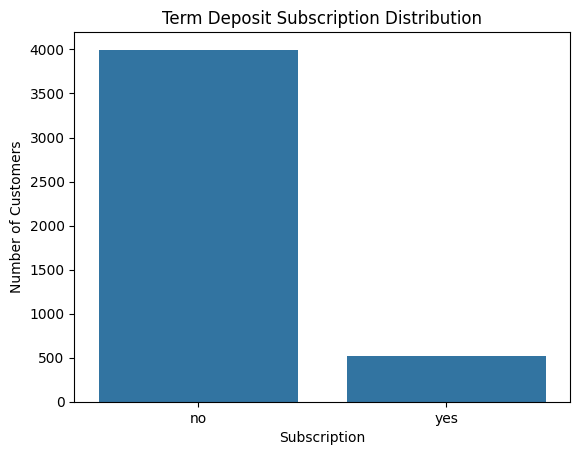

In [25]:
sns.countplot(data=df, x="y")
plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()

Total customers 4,517

Subscribed % of conversion 520 11.51%

Not subscribed 3,997 88.49%

Business Insight: Out of 4,517 customers, only 520 (11.51%) subscribed to a term deposit, while 3,997 (88.49%) did not subscribe. This indicates a low overall subscription rate.

Recommendation: The bank should focus on identifying high-potential customers and improving targeted marketing strategies to increase conversion rates.

2. Analyze customer age

In [26]:
print(df["age"].describe())

count    4517.000000
mean       41.160505
std        10.564311
min        19.000000
25%        33.000000
50%        39.000000
75%        49.000000
max        87.000000
Name: age, dtype: float64


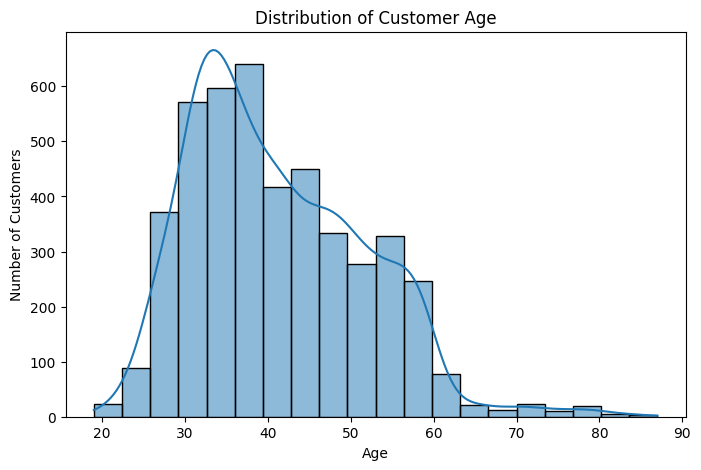

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

mean       41.160505
std        10.564311
min        19.000000
25%        33.000000
50%        39.000000
75%        49.000000
max        87.000000

Business Insight:
           The average customer age is approximately 41 years, and half of the customers are between 33 and 49 years old. This indicates that the data contains set of middle-aged customers.

Recommendation:
           The bank can develop marketing campaigns suited to middle-aged customers while separately examining subscription rates across age groups to identify the most responsive customers.

3. Analyze bank balance

count     4517.000000
mean      1413.964135
std       2978.327044
min      -3313.000000
25%         69.000000
50%        444.000000
75%       1477.000000
max      71188.000000
Name: balance, dtype: float64


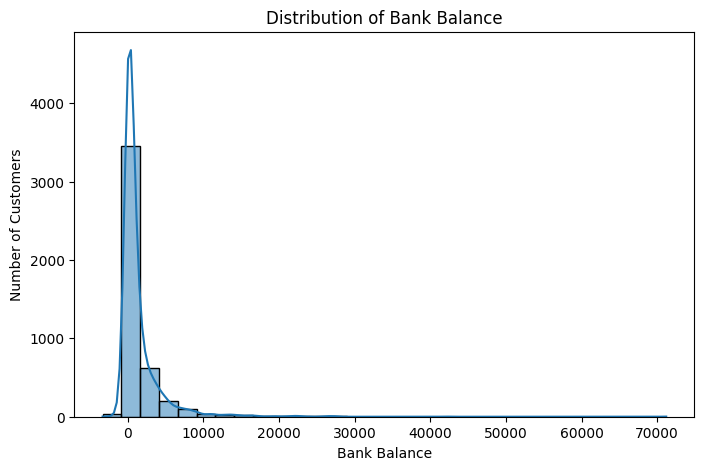

In [28]:
print(df["balance"].describe())

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="balance", bins=30, kde=True)
plt.title("Distribution of Bank Balance")
plt.xlabel("Bank Balance")
plt.ylabel("Number of Customers")
plt.show()

mean 1413.964135 std 2978.327044 min -3313.000000 25% 69.000000 50% 444.000000 75% 1477.000000 max 71188.000000

Business Insight:
       The average bank balance is significantly higher than the median, indicating a positively skewed distribution. A small number of customers with very high balances increase the average. Some customers also have negative balances.

Recommendation:
       The bank should segment customers based on account balance and investigate whether customers with higher balances have greater subscription potential. Median balance may be more representative than mean balance for typical customers.

Bivariate analysis

1. Subscription rate by job

job
retired          23.58
student          22.62
unknown          18.42
management       13.44
housemaid        12.50
admin.           12.16
self-employed    10.93
technician       10.81
unemployed       10.16
services          9.11
entrepreneur      8.93
blue-collar       7.29
Name: y, dtype: float64


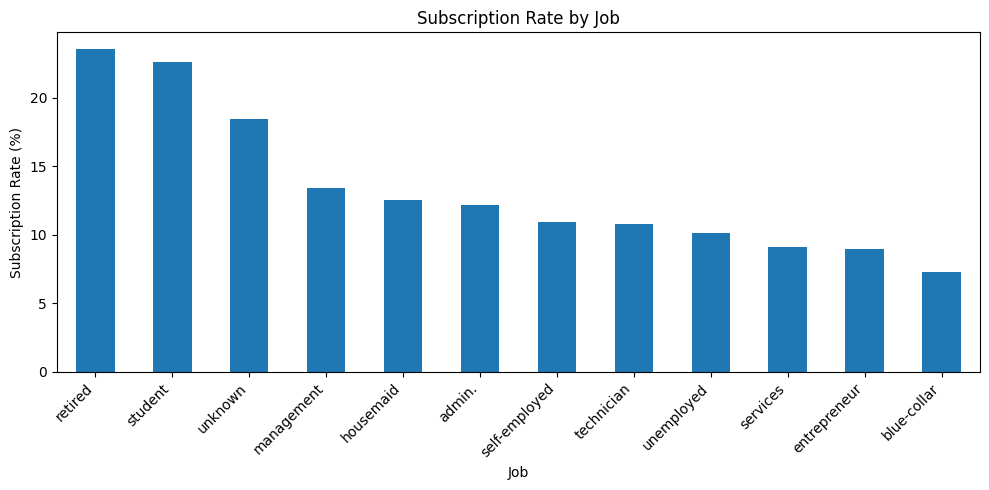

In [29]:
job_rate = (
    df.groupby("job", observed=True)["y"]
      .apply(lambda x: x.eq("yes").mean() * 100)
      .sort_values(ascending=False)
)

print(job_rate.round(2))

job_rate.plot(kind="bar", figsize=(10, 5))
plt.title("Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Business Insight:
         Retired customers have the highest subscription rate at 23.58%, followed by students at 22.62%. Blue-collar workers have the lowest subscription rate at 7.29%.
         This suggests that occupation is associated with customers' willingness to subscribe to term deposits.
Recommendation:
         The bank should prioritize testing targeted campaigns for retired customers and students.

2. Subscription rate by marital status

In [46]:
marital_rate = (
    df.groupby("marital", observed=True)["y"]
    .apply(lambda x: x.eq("yes").mean() * 100)
    .reset_index(name="Subscription Rate")
)
print(marital_rate.round(2))
fig = px.pie(
   marital_rate,
    names="marital",
    values="Subscription Rate",
    title="Subscription Rate by Marital Status",
    hole=0,
    color="marital",
    )

fig.show()

    marital  Subscription Rate
0  divorced              14.58
1   married               9.91
2    single              13.90


Business Insight:
           Divorced customers have the highest subscription rate (14.58%), followed by single customers (13.90%). Married customers have the lowest subscription rate (9.91%).
Recommendation:
          The bank can evaluate customized marketing strategies for different marital-status groups. However, marital status should not be treated as a direct cause of subscription behavior.


3. Subscription rate by education

education
tertiary     14.25
secondary    10.63
unknown      10.16
primary       9.44
Name: y, dtype: float64


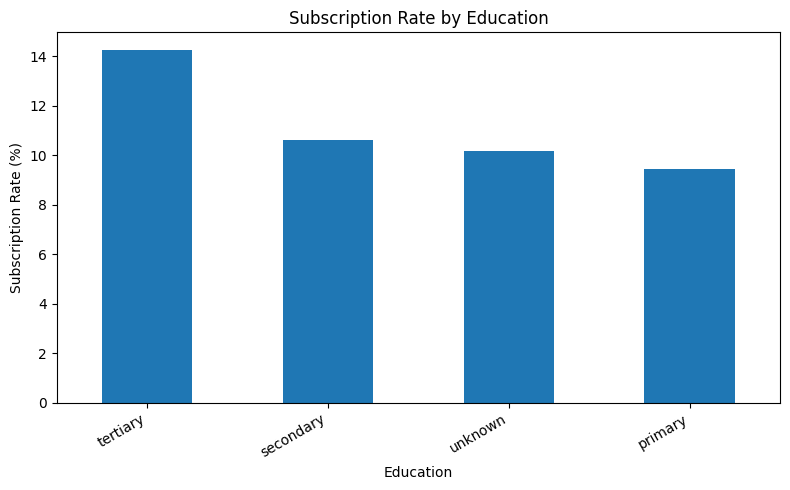

In [32]:
education_rate = (
    df.groupby("education", observed=True)["y"]
      .apply(lambda x: x.eq("yes").mean() * 100)
      .sort_values(ascending=False)
)

print(education_rate.round(2))

education_rate.plot(kind="bar", figsize=(8, 5))
plt.title("Subscription Rate by Education")
plt.xlabel("Education")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Business Insight:
          Overall, customers with tertiary education show a higher tendency to subscribe to term deposits than customers in the other education groups.
          
Recommendation:
          Explore targeted campaigns for customers with tertiary education, as this group has the highest observed subscription rate.Provide clear and simple explanations of term deposit benefits to customers across all education levels.Collect missing education information to better understand customer segments.

4. Subscription rate by month

month
jan    10.81
feb    17.19
mar    42.86
apr    19.11
may     6.65
jun    10.38
jul     8.65
aug    12.48
sep    31.37
oct    46.25
nov    10.03
dec    45.00
Name: y, dtype: float64


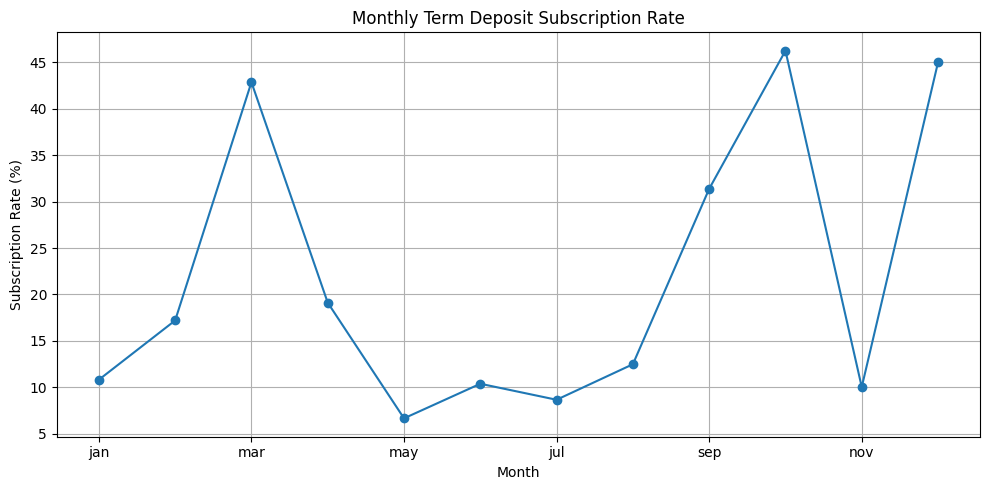

In [50]:
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

monthly_rate = (
    df.groupby("month", observed=True)["y"]
      .apply(lambda x: x.eq("yes").mean() * 100)
      .reindex(month_order)
      .dropna()
)

print(monthly_rate.round(2))

monthly_rate.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Monthly Term Deposit Subscription Rate")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()


Business Insight:
         October recorded the highest subscription rate (46.25%), followed by December (45%) and March (42.86%). May recorded the lowest subscription rate (6.65%).
         This indicates substantial variation in campaign performance across months.
Recommendation:
         The bank should investigate why certain months achieved higher subscription rates and evaluate whether campaign timing, customer selection, or contact volumes contributed to these differences. Monthly sample sizes should be checked before drawing seasonal conclusions.

Campaign performance analysis

1. Number of contacts and subscription

      count      mean       std  min  25%  50%  75%   max
y                                                        
no   3997.0  2.863147  3.213621  1.0  1.0  2.0  3.0  50.0
yes   520.0  2.267308  2.094053  1.0  1.0  2.0  3.0  24.0


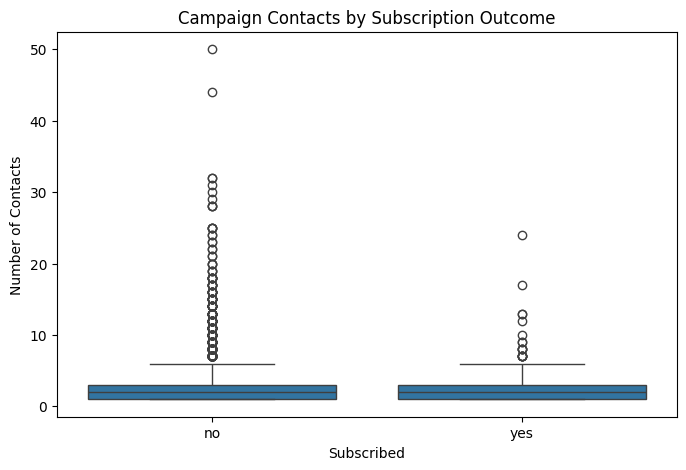

In [34]:
print(df.groupby("y")["campaign"].describe())

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="y", y="campaign")
plt.title("Campaign Contacts by Subscription Outcome")
plt.xlabel("Subscribed")
plt.ylabel("Number of Contacts")
plt.show()

Business Insight:
         Customers who subscribed were contacted approximately 2.28 times on average, compared with 2.86 times for customers who did not subscribe.
         The results suggest that successful subscriptions are associated with fewer campaign contacts. However, they do not prove that additional contacts cause customers to reject an offer.
         
Recommendation:
         The bank should evaluate contact frequency and consider limiting repeated unsuccessful calls to reduce operational costs and improve customer experience.

2. Call duration versus subscription

y
no     167.0
yes    444.0
Name: duration, dtype: float64


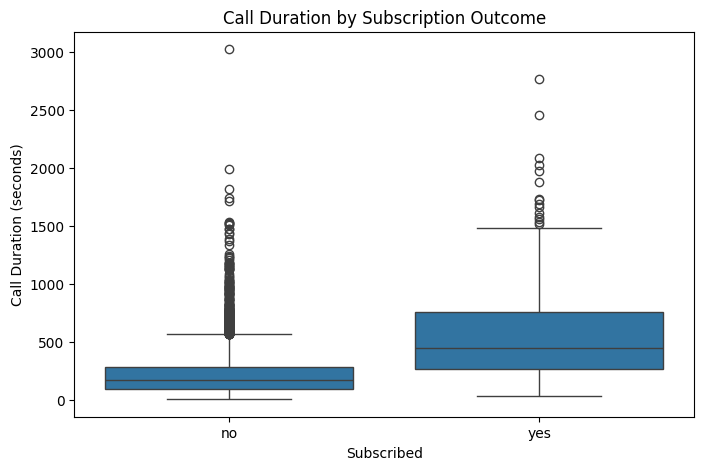

In [35]:
print(df.groupby("y")["duration"].median())

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="y", y="duration")
plt.title("Call Duration by Subscription Outcome")
plt.xlabel("Subscribed")
plt.ylabel("Call Duration (seconds)")
plt.show()

Business Insight:
         Call duration of Subscribed customers is higher than compared to Non-subscribed customers.
         
Recommendation:
         Train marketing staff to explain term deposit benefits clearly and address customer questions effectively resulted in subscriptions.Focus on meaningful conversations and track campaign effectiveness.

3. Subscription rate by housing loan

housing
no     15.36
yes     8.56
Name: y, dtype: float64


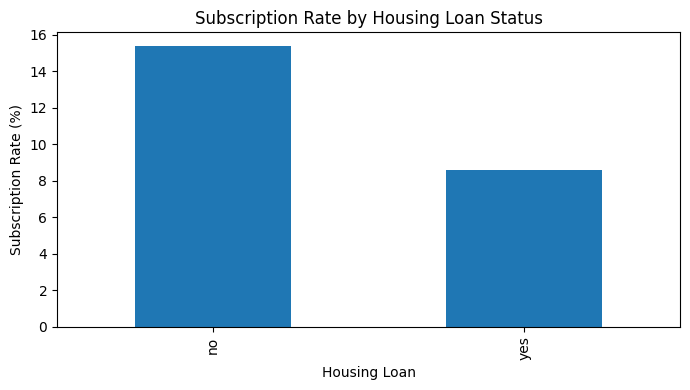

In [36]:
housing_rate = (
    df.groupby("housing", observed=True)["y"]
      .apply(lambda x: x.eq("yes").mean() * 100)
)

print(housing_rate.round(2))

housing_rate.plot(kind="bar", figsize=(7, 4))
plt.title("Subscription Rate by Housing Loan Status")
plt.xlabel("Housing Loan")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

Business Insight:
        Customers without housing loans have a higher term deposit subscription rate (15.36%) compared with customers who have housing loans (8.56%).
        This suggests that housing loan status is associated with subscription decisions.
        
Recommendation:
        The bank should investigate customers' existing financial commitments when designing deposit campaigns and test whether customers without housing loans respond more positively.

Correlation analysis

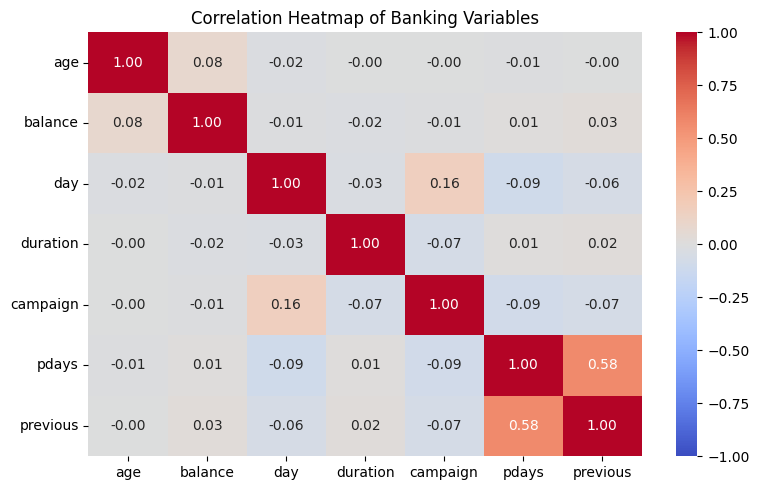

In [47]:
numeric_cols = [
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap of Banking Variables")
plt.tight_layout()
plt.show()

Business Insight:

+1: Perfect positive correlation
-1: Perfect negative correlation
0: Little or no linear correlation


pdays and previous	+0.58	Moderate positive relationship between previous contact timing and the number of previous contacts.

day and campaign	+0.16	Weak positive relationship between the day of the month and campaign contacts.

age and balance	+0.08	Very weak positive relationship between customer age and bank balance.

campaign and duration	-0.07	Very weak negative relationship between campaign contact count and call duration.

campaign and pdays	-0.09	Very weak negative relationship between campaign contact count and days since a previous contact.

age and duration	Approximately 0.00	Almost no linear relationship between customer age and call duration.

Recommendation:
Analyze previous campaign outcomes and contact timing to improve customer re-engagement strategies.Evaluate the relationship between contact frequency and subscription success


Business KPIs

In [38]:
total_customers = len(df)
subscribed = df["y"].eq("yes").sum()
not_subscribed = df["y"].eq("no").sum()
subscription_rate = (subscribed / total_customers) * 100
print("Total Customers:", total_customers)
print("Subscribed Customers:", subscribed)
print("Non-Subscribed Customers:", not_subscribed)
print(f"Subscription Rate: {subscription_rate:.2f}%")
print(f"Non-Subscription Rate: {(100 - subscription_rate):.2f}%")


Total Customers: 4517
Subscribed Customers: 520
Non-Subscribed Customers: 3997
Subscription Rate: 11.51%
Non-Subscription Rate: 88.49%


BUSINESS INSIGHTS

A. **Term deposit subscription Status**

Business Insight:
      Out of 4,517 customers, only 520 (11.51%) subscribed to a term deposit, while 3,997 (88.49%) did not subscribe. This indicates a low overall subscription rate.

Recommendation:
      The bank should focus on identifying high-potential customers and improving targeted marketing strategies to increase conversion rates.      


B. **Age Analysis**


mean       41.160505
std        10.564311
min        19.000000
25%        33.000000
50%        39.000000
75%        49.000000
max        87.000000

Business Insight:
           The average customer age is approximately 41 years, and half of the customers are between 33 and 49 years old. This indicates that the data contains set of middle-aged customers.

Recommendation:
           The bank can develop marketing campaigns suited to middle-aged customers while separately examining subscription rates across age groups to identify the most responsive customers.


C. Bank Balance Analysis

mean 1413.964135 std 2978.327044 min -3313.000000 25% 69.000000 50% 444.000000 75% 1477.000000 max 71188.000000

Business Insight:
       The average bank balance is significantly higher than the median, indicating a positively skewed distribution. A small number of customers with very high balances increase the average. Some customers also have negative balances.

Recommendation:
       The bank should segment customers based on account balance and investigate whether customers with higher balances have greater subscription potential. Median balance may be more representative than mean balance for typical customers.

D. Subscription Rate by Job Category

job
retired          23.58
student          22.62
unknown          18.42
management       13.44
housemaid        12.50
admin.           12.16
self-employed    10.93
technician       10.81
unemployed       10.16
services          9.11
entrepreneur      8.93
blue-collar       7.29

Business Insight:
         Retired customers have the highest subscription rate at 23.58%, followed by students at 22.62%. Blue-collar workers have the lowest subscription rate at 7.29%.
         This suggests that occupation is associated with customers' willingness to subscribe to term deposits.
Recommendation:
         The bank should prioritize testing targeted campaigns for retired customers and students.

E. Subscription Rate by Marital Status

marital
divorced    14.58
single      13.90
married      9.91

Business Insight:
           Divorced customers have the highest subscription rate (14.58%), followed by single customers (13.90%). Married customers have the lowest subscription rate (9.91%).
Recommendation:
          The bank can evaluate customized marketing strategies for different marital-status groups. However, marital status should not be treated as a direct cause of subscription behavior.


F. Monthly Subscription Rate Analysis

month
jan    10.81
feb    17.19
mar    42.86
apr    19.11
may     6.65
jun    10.38
jul     8.65
aug    12.48
sep    31.37
oct    46.25
nov    10.03
dec    45.00


Business Insight:
         October recorded the highest subscription rate (46.25%), followed by December (45%) and March (42.86%). May recorded the lowest subscription rate (6.65%).
         This indicates substantial variation in campaign performance across months.
Recommendation:
         The bank should investigate why certain months achieved higher subscription rates and evaluate whether campaign timing, customer selection, or contact volumes contributed to these differences. Monthly sample sizes should be checked before drawing seasonal conclusions.

G. Number of Campaign Contacts and Subscription

y   count  mean  std  min  25%  50%  75%  max
                                           
no   3997  2.86  3.21  1.0  1.0  2.0  3.0  50

yes   520  2.26  2.09  1.0  1.0  2.0  3.0  24

Business Insight:
         Customers who subscribed were contacted approximately 2.28 times on average, compared with 2.86 times for customers who did not subscribe.
         The results suggest that successful subscriptions are associated with fewer campaign contacts. However, they do not prove that additional contacts cause customers to reject an offer.
Recommendation:
         The bank should evaluate contact frequency and consider limiting repeated unsuccessful calls to reduce operational costs and improve customer experience.

H. Subscription Rate by Housing Loan Status

Without HL    With HL

15.36%        8.56%

Business Insight:
        Customers without housing loans have a higher term deposit subscription rate (15.36%) compared with customers who have housing loans (8.56%).
        This suggests that housing loan status is associated with subscription decisions.
Recommendation:
        The bank should investigate customers' existing financial commitments when designing deposit campaigns and test whether customers without housing loans respond more positively.

## Conclusion

The Bank Marketing Campaign Analysis project was conducted using Python to understand customer behavior and identify factors associated with term deposit subscriptions.

The analysis included 4,517 customers, of whom 520 (11.51%) subscribed to a term deposit, while 3,997 (88.49%) did not. This indicates a low overall campaign conversion rate.

The analysis revealed that retired customers and students had the highest subscription rates among occupational groups. Customers with tertiary education, divorced and single customers, and customers without housing loans also demonstrated comparatively higher subscription rates.

Monthly analysis showed that October, December, and March achieved the highest observed subscription rates. Campaign contact analysis indicated that successful subscribers received fewer contacts on average than customers who did not subscribe.

The correlation analysis showed that most numerical variables had weak linear relationships, with a moderate positive correlation between previous campaign contact variables.

Overall, the findings suggest that customer characteristics, financial circumstances, and campaign practices are associated with term deposit subscription outcomes.

**The bank can use these insights to improve customer segmentation, refine marketing strategies, reduce unnecessary contact attempts, and identify opportunities to increase campaign effectiveness.** Further statistical analysis and predictive modeling are recommended to validate these patterns and support data-driven decision-making.